In [30]:
from pathlib import Path
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [31]:
# Configuração visual padrão para todo o projeto
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"

PASTA_IMAGENS = Path("images")
PASTA_IMAGENS.mkdir(exist_ok=True)

# Paleta fixa por ano (mantém consistência visual em todos os notebooks)
CORES_ANO = {
    #2024: "#548BD8",  # Ardósia (fase inicial pré-pausa)
    2024: "#C544BF",  # Ardósia (fase inicial pré-pausa)
    2025: "#F59E0B",  # Âmbar (ano irregular / destreinamento)
    2026: "#0D9488",  # Verde-petróleo (retomada consistente)
}

In [38]:
def fmt_pace_eixo(val, _pos=None):
  """Converte pace decimal (ex: 5.50) para formato relógio (5:30)."""
  if pd.isna(val) or val <= 0:
    return ""
  total_seg = int(round(val * 60))
  minutos, segundos = divmod(total_seg, 60)
  return f"{minutos}:{segundos:02d}"

In [39]:
# 1. Carregamento da base consolidada pelo ETL
df_raw = pd.read_csv("df_corridas.csv")
df_raw["data"] = pd.to_datetime(df_raw["data"], format="mixed")

# 2. Aplicação dos filtros de negócio (corridas reais de rua, sem caminhadas)
df = df_raw[
    (df_raw["modalidade"] == "Rua")
    & (df_raw["distancia_km"] >= 2.0)
    & (df_raw["pace_dec"] < 8.0)
].copy()

# Restaura a ordem categórica das faixas (perdida ao salvar/ler CSV)
ordem_faixas = [
    "Curto (2-4.89K)",
    "Base 5K",
    "5-6K",
    "Base 6K",
    "6-7K",
    "Base 7K",
    "7-8K",
    "Base 8K",
    "8-10K",
    "Base 10K",
    "+10K",
]
df["faixa_distancia"] = pd.Categorical(
    df["faixa_distancia"], categories=ordem_faixas, ordered=True
)

# 3. Engenharia de métricas macro
# Velocidade média (m/min) dividida pelo BPM médio (mesma régua do df_por_km)
vel_m_min = 1000.0 / df["pace_dec"]
df["eficiencia_aerobica"] = (vel_m_min / df["bpm_medio"]).round(3)
df["elevacao_por_km"] = (df["ganho_elev_total_m"] / df["distancia_km"]).round(1)

print(
    f"Sessões totais no CSV: {len(df_raw)} | "
    f"Corridas válidas após filtros: {len(df)} "
    f"({len(df_raw) - len(df)} removidas por esteira, <2km ou caminhada >8:00/km)"
)

# 4. Tabela Executiva por Ano
resumo_anual = (
    df.groupby("ano")
    .agg(
        corridas=("record_id", "count"),
        volume_total_km=("distancia_km", "sum"),
        dist_media_km=("distancia_km", "mean"),
        pace_medio_dec=("pace_dec", "mean"),
        melhor_pace_dec=("pace_dec", "min"),
        bpm_medio=("bpm_medio", "mean"),
        eficiencia_media=("eficiencia_aerobica", "mean"),
        elev_por_km=("elevacao_por_km", "mean"),
        peso_medio_kg=("peso_kg", "mean"),
    )
    .round(2)
)

resumo_anual["pace_medio"] = resumo_anual["pace_medio_dec"].apply(fmt_pace_eixo)
resumo_anual["melhor_pace"] = resumo_anual["melhor_pace_dec"].apply(fmt_pace_eixo)

cols_exibir = [
    "corridas",
    "volume_total_km",
    "dist_media_km",
    "pace_medio",
    "melhor_pace",
    "bpm_medio",
    "eficiencia_media",
    "elev_por_km",
    "peso_medio_kg",
]
print("\n=== RESUMO EXECUTIVO POR ANO (CORRIDAS DE RUA >= 2 KM) ===")
print(resumo_anual[cols_exibir].to_string())

Sessões totais no CSV: 227 | Corridas válidas após filtros: 198 (29 removidas por esteira, <2km ou caminhada >8:00/km)

=== RESUMO EXECUTIVO POR ANO (CORRIDAS DE RUA >= 2 KM) ===
      corridas  volume_total_km  dist_media_km pace_medio melhor_pace  bpm_medio  eficiencia_media  elev_por_km  peso_medio_kg
ano                                                                                                                           
2024        20           118.20           5.91       5:46        5:14     156.75               inf        13.72          74.46
2025        50           243.40           4.87       7:02        6:08     153.54               inf        13.91          86.31
2026       128           764.35           5.97       6:23        4:35     150.20              1.06        14.56          82.26


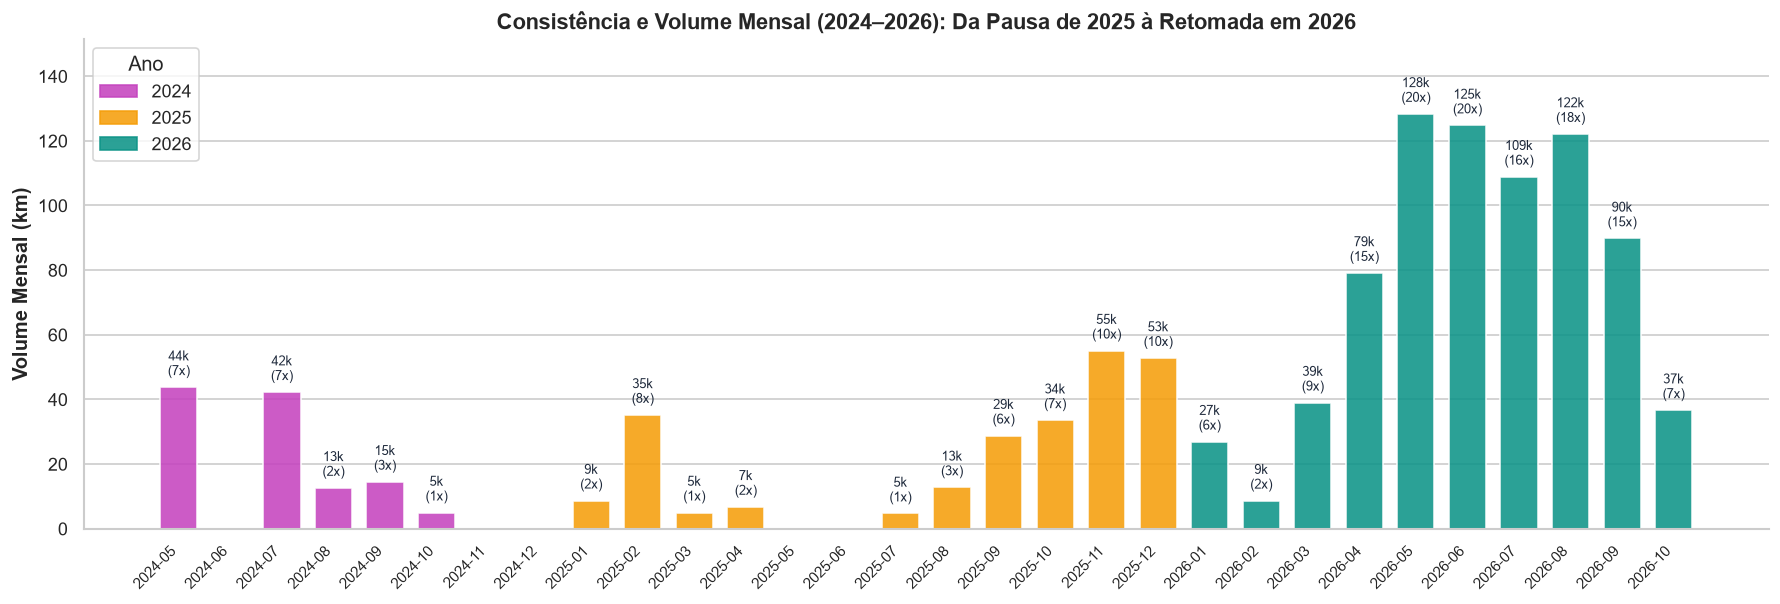

In [33]:
# Cria grade completa de meses entre a primeira e a última corrida (inclui meses zerados)
todos_meses = pd.period_range(
    df["data"].min().to_period("M"), df["data"].max().to_period("M"), freq="M"
)

mensal = (
    df.assign(mes_periodo=df["data"].dt.to_period("M"))
    .groupby("mes_periodo")
    .agg(
        volume_km=("distancia_km", "sum"),
        qtd_corridas=("record_id", "count"),
    )
    .reindex(todos_meses, fill_value=0)
    .reset_index()
    .rename(columns={"index": "mes_periodo"})
)

mensal["ano"] = mensal["mes_periodo"].dt.year
mensal["mes_label"] = mensal["mes_periodo"].dt.strftime("%Y-%m")
cores_barras = [CORES_ANO[a] for a in mensal["ano"]]

fig, ax1 = plt.subplots(figsize=(15, 5.2))

x = np.arange(len(mensal))
barras = ax1.bar(x, mensal["volume_km"], color=cores_barras, alpha=0.88, width=0.72)

ax1.set_ylabel("Volume Mensal (km)", fontweight="bold")
ax1.set_ylim(0, mensal["volume_km"].max() * 1.18)
ax1.set_xticks(x)
ax1.set_xticklabels(mensal["mes_label"], rotation=45, ha="right", fontsize=9)
ax1.grid(axis="x", visible=False)

# Rótulos de volume acima das barras com atividade
for idx, row in mensal.iterrows():
  if row["volume_km"] > 0:
    ax1.text(
        idx,
        row["volume_km"] + 2.5,
        f"{row['volume_km']:.0f}k\n({int(row['qtd_corridas'])}x)",
        ha="center",
        va="bottom",
        fontsize=7.8,
        color="#1E293B",
    )

# Legenda manual por ano
handles = [
    plt.Rectangle((0, 0), 1, 1, color=CORES_ANO[a], alpha=0.88, label=str(a))
    for a in sorted(CORES_ANO)
]
ax1.legend(handles=handles, title="Ano", frameon=True, loc="upper left")
ax1.set_title(
    "Consistência e Volume Mensal (2024–2026): Da Pausa de 2025 à Retomada em 2026"
)

sns.despine(top=True, right=True)
plt.tight_layout()
plt.savefig(PASTA_IMAGENS / "01_volume_mensal_2024_2026.png")
plt.show()

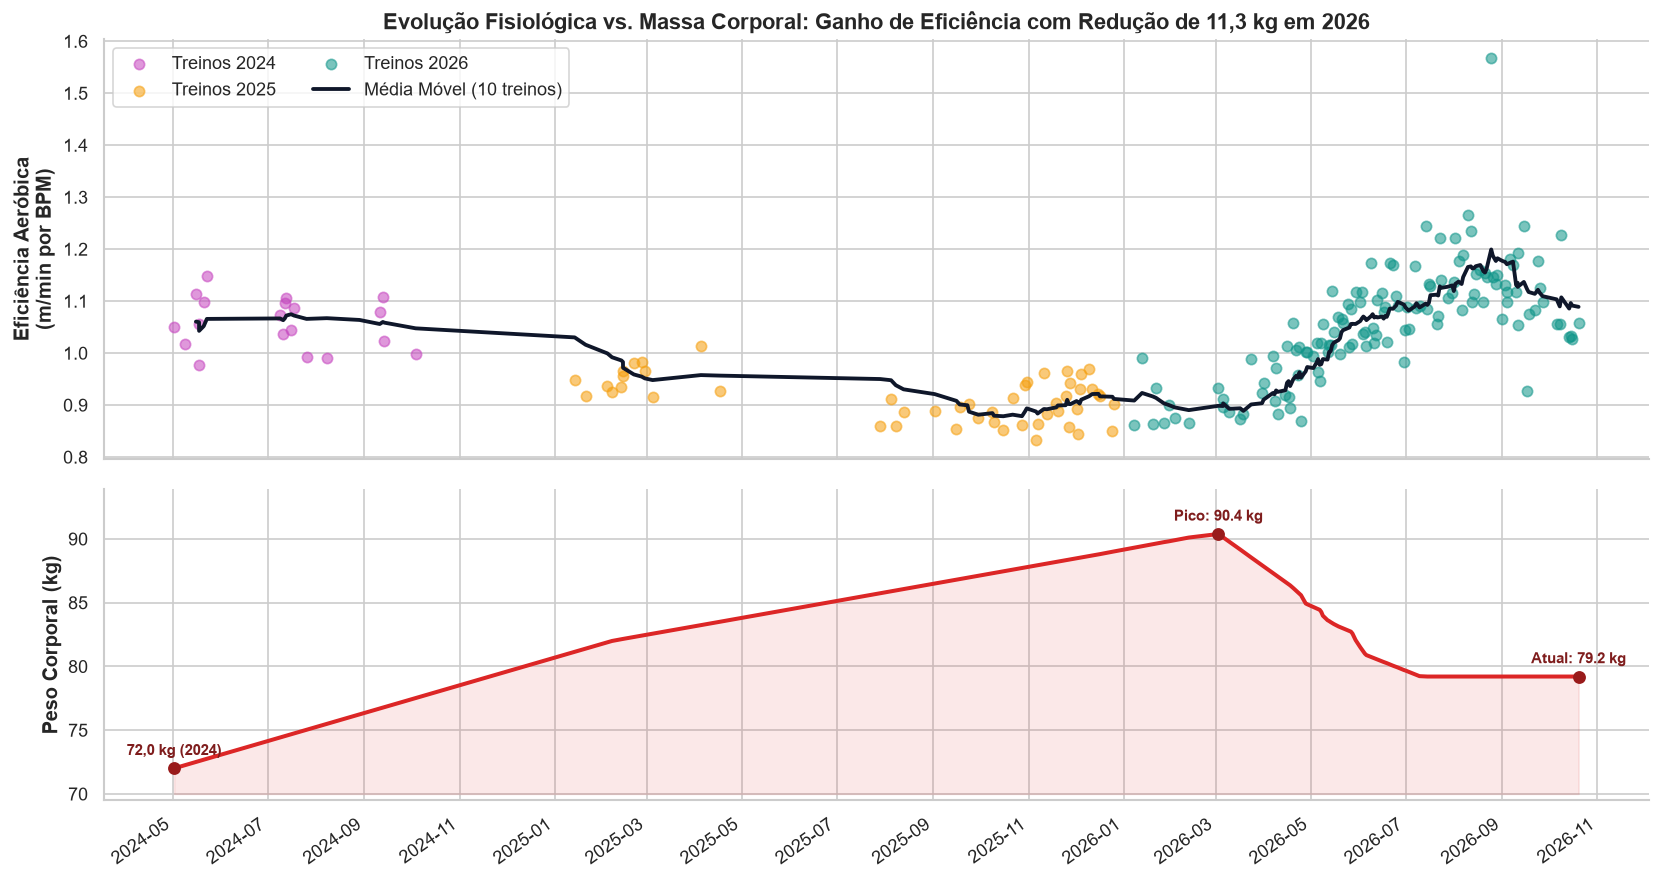

In [34]:
df_ord = df.sort_values("data").copy()
df_ord["eficiencia_mm10"] = (
    df_ord["eficiencia_aerobica"].rolling(window=10, min_periods=3).mean()
)

fig, (ax_top, ax_bot) = plt.subplots(
    2,
    1,
    figsize=(14, 7.5),
    sharex=True,
    gridspec_kw={"height_ratios": [1.35, 1]},
)

# Painel Superior: Eficiência Aeróbica (velocidade m/min por batimento)
for ano, grp in df_ord.groupby("ano"):
  ax_top.scatter(
      grp["data"],
      grp["eficiencia_aerobica"],
      color=CORES_ANO[ano],
      alpha=0.55,
      s=38,
      label=f"Treinos {ano}",
  )

ax_top.plot(
    df_ord["data"],
    df_ord["eficiencia_mm10"],
    color="#0F172A",
    linewidth=2.3,
    label="Média Móvel (10 treinos)",
)
ax_top.set_ylabel("Eficiência Aeróbica\n(m/min por BPM)", fontweight="bold")
ax_top.set_title(
    "Evolução Fisiológica vs. Massa Corporal: Ganho de Eficiência com Redução de 11,3 kg em 2026"
)
ax_top.legend(loc="upper left", frameon=True, ncol=2)

# Painel Inferior: Curva de Peso Corporal
ax_bot.plot(
    df_ord["data"],
    df_ord["peso_kg"],
    color="#DC2626",
    linewidth=2.4,
    label="Peso Corporal (kg)",
)
ax_bot.fill_between(
    df_ord["data"],
    df_ord["peso_kg"],
    df_ord["peso_kg"].min() - 2,
    color="#DC2626",
    alpha=0.10,
)

# Anotações dos marcos principais de peso
marcos_peso = [
    (df_ord.iloc[0]["data"], df_ord.iloc[0]["peso_kg"], "72,0 kg (2024)"),
    (
        df_ord.loc[df_ord["peso_kg"].idxmax(), "data"],
        df_ord["peso_kg"].max(),
        f"Pico: {df_ord['peso_kg'].max():.1f} kg",
    ),
    (
        df_ord.iloc[-1]["data"],
        df_ord.iloc[-1]["peso_kg"],
        f"Atual: {df_ord.iloc[-1]['peso_kg']:.1f} kg",
    ),
]
for dt_m, p_m, txt_m in marcos_peso:
  ax_bot.scatter([dt_m], [p_m], color="#991B1B", zorder=5, s=45)
  ax_bot.annotate(
      txt_m,
      xy=(dt_m, p_m),
      xytext=(0, 8),
      textcoords="offset points",
      ha="center",
      fontsize=9,
      fontweight="bold",
      color="#7F1D1D",
  )

ax_bot.set_ylabel("Peso Corporal (kg)", fontweight="bold")
ax_bot.set_ylim(df_ord["peso_kg"].min() - 2.5, df_ord["peso_kg"].max() + 3.5)
ax_bot.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax_bot.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
plt.xticks(rotation=35, ha="right")

sns.despine(top=True, right=True)
plt.tight_layout()
plt.savefig(PASTA_IMAGENS / "02_eficiencia_vs_peso_corporal.png")
plt.show()

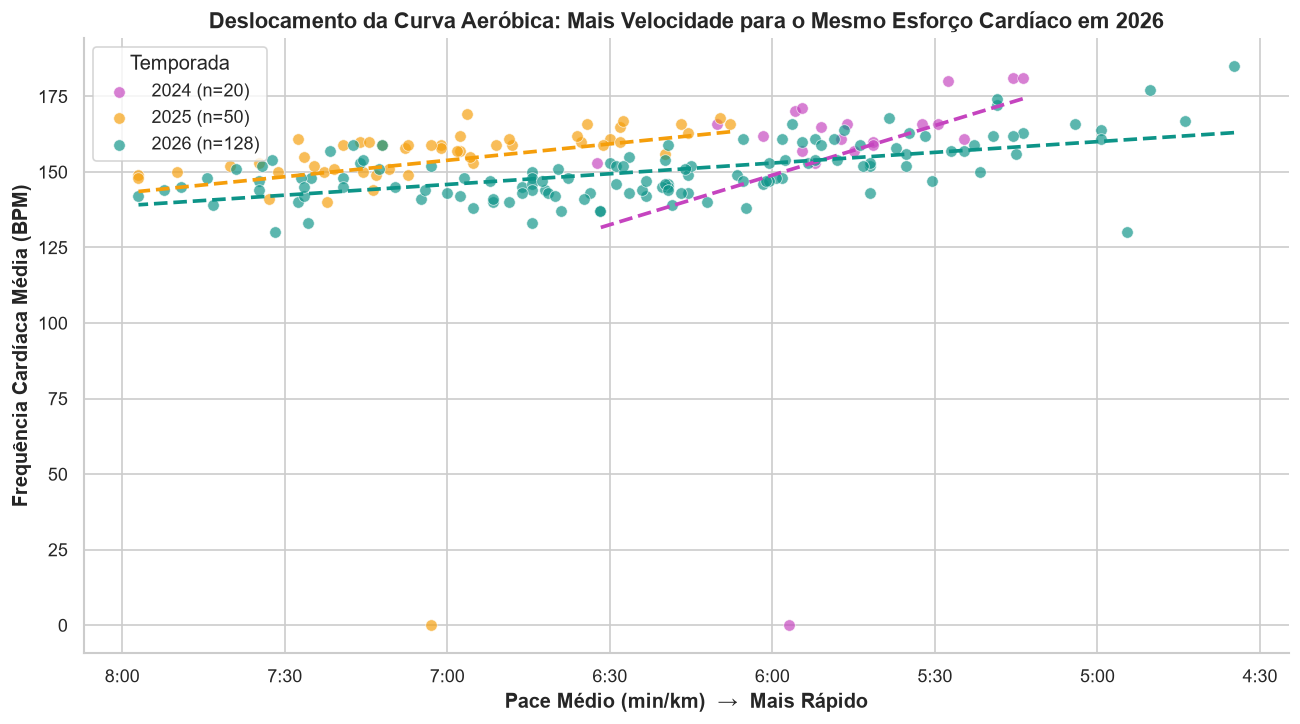

In [35]:
fig, ax = plt.subplots(figsize=(11, 6.2))

for ano in sorted(df["ano"].unique()):
  sub = df[df["ano"] == ano].dropna(subset=["pace_dec", "bpm_medio"])
  ax.scatter(
      sub["pace_dec"],
      sub["bpm_medio"],
      color=CORES_ANO[ano],
      alpha=0.68,
      s=48,
      edgecolors="white",
      linewidth=0.5,
      label=f"{ano} (n={len(sub)})",
  )
  # Linha de tendência linear por ano
  if len(sub) >= 5:
    sns.regplot(
        data=sub,
        x="pace_dec",
        y="bpm_medio",
        scatter=False,
        ax=ax,
        color=CORES_ANO[ano],
        ci=None,
        line_kws={"linewidth": 2.2, "linestyle": "--"},
    )

# Inverte o eixo X para que avançar para a direita signifique correr mais rápido
ax.invert_xaxis()
ax.xaxis.set_major_formatter(FuncFormatter(fmt_pace_eixo))

ax.set_xlabel("Pace Médio (min/km)  →  Mais Rápido", fontweight="bold")
ax.set_ylabel("Frequência Cardíaca Média (BPM)", fontweight="bold")
ax.set_title(
    "Deslocamento da Curva Aeróbica: Mais Velocidade para o Mesmo Esforço Cardíaco em 2026"
)
ax.legend(title="Temporada", frameon=True, loc="upper left")

sns.despine(top=True, right=True)
plt.tight_layout()
plt.savefig(PASTA_IMAGENS / "03_pace_vs_bpm_por_ano.png")
plt.show()

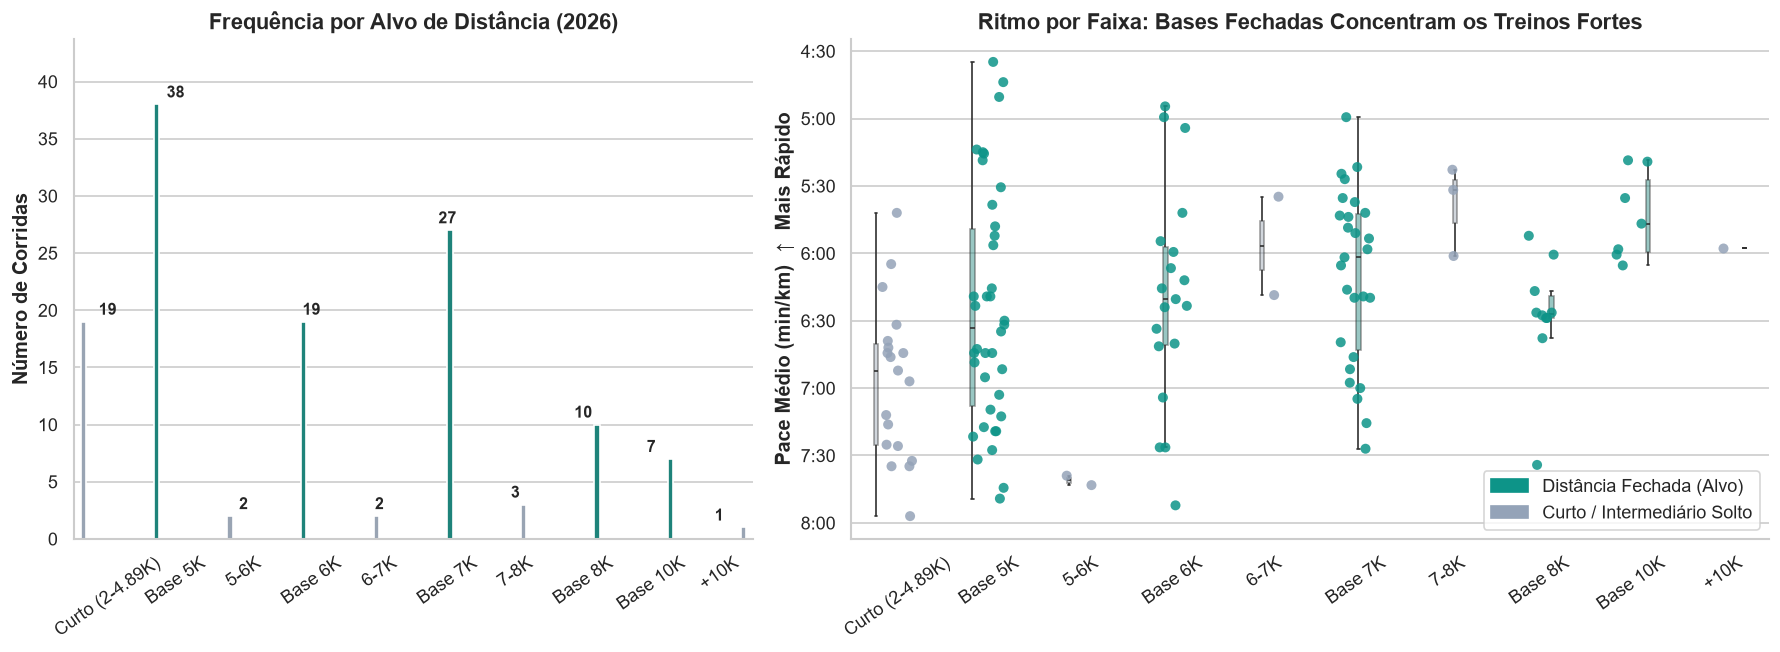

=== COMPARATIVO 2026: DISTÂNCIA FECHADA VS. SOLTA ===
                   corridas pace_medio melhor_pace  bpm_medio  eficiencia
distancia_fechada                                                        
False                    27       6:45        5:23    146.667       1.025
True                    101       6:17        4:35    151.149       1.067


In [36]:
df_2026 = df[df["ano"] == 2026].copy()

# Remove categorias zeradas (como '8-10K') ANTES de contar e montar a paleta
df_2026["faixa_distancia"] = df_2026[
    "faixa_distancia"
].cat.remove_unused_categories()

contagem_faixas = df_2026["faixa_distancia"].value_counts(sort=False)
faixas_ativas = contagem_faixas.index.tolist()

bases_fechadas = {"Base 5K", "Base 6K", "Base 7K", "Base 8K", "Base 10K"}
paleta_faixas = {
    f: ("#0D9488" if f in bases_fechadas else "#94A3B8") for f in faixas_ativas
}

fig, (ax_vol, ax_box) = plt.subplots(
    1, 2, figsize=(15, 5.6), gridspec_kw={"width_ratios": [1, 1.35]}
)

# Esquerda: Volume de treinos por faixa
sns.barplot(
    x=contagem_faixas.index,
    y=contagem_faixas.values,
    hue=contagem_faixas.index,
    palette=paleta_faixas,
    legend=False,
    ax=ax_vol,
)
for i, v in enumerate(contagem_faixas.values):
  ax_vol.text(i, v + 0.6, str(v), ha="center", fontweight="bold", fontsize=9.5)

ax_vol.set_title("Frequência por Alvo de Distância (2026)")
ax_vol.set_xlabel("")
ax_vol.set_ylabel("Número de Corridas", fontweight="bold")
ax_vol.set_ylim(0, contagem_faixas.max() * 1.15)
ax_vol.tick_params(axis="x", rotation=35)

# Direita: Distribuição de pace por faixa (boxplot + pontos reais)
sns.boxplot(
    data=df_2026,
    x="faixa_distancia",
    y="pace_dec",
    hue="faixa_distancia",
    palette=paleta_faixas,
    legend=False,
    width=0.52,
    fliersize=0,
    boxprops={"alpha": 0.45},
    ax=ax_box,
)
sns.stripplot(
    data=df_2026,
    x="faixa_distancia",
    y="pace_dec",
    hue="faixa_distancia",
    palette=paleta_faixas,
    legend=False,
    size=6,
    jitter=0.18,
    alpha=0.85,
    ax=ax_box,
)

ax_box.invert_yaxis()
ax_box.yaxis.set_major_formatter(FuncFormatter(fmt_pace_eixo))
ax_box.set_title("Ritmo por Faixa: Bases Fechadas Concentram os Treinos Fortes")
ax_box.set_xlabel("")
ax_box.set_ylabel("Pace Médio (min/km)  ↑  Mais Rápido", fontweight="bold")
ax_box.tick_params(axis="x", rotation=35)

# Legenda explicando a regra de negócio
leg_handles = [
    plt.Rectangle((0, 0), 1, 1, color="#0D9488", label="Distância Fechada (Alvo)"),
    plt.Rectangle((0, 0), 1, 1, color="#94A3B8", label="Curto / Intermediário Solto"),
]
ax_box.legend(handles=leg_handles, loc="lower right", frameon=True)

sns.despine(top=True, right=True)
plt.tight_layout()
plt.savefig(PASTA_IMAGENS / "04_validacao_faixas_distancia_2026.png")
plt.show()

# Resumo numérico comparando fechadas vs. não fechadas em 2026
print("=== COMPARATIVO 2026: DISTÂNCIA FECHADA VS. SOLTA ===")
comp_fechada = (
    df_2026.groupby("distancia_fechada")
    .agg(
        corridas=("record_id", "count"),
        pace_medio_dec=("pace_dec", "mean"),
        melhor_pace_dec=("pace_dec", "min"),
        bpm_medio=("bpm_medio", "mean"),
        eficiencia=("eficiencia_aerobica", "mean"),
    )
    .round(3)
)
comp_fechada["pace_medio"] = comp_fechada["pace_medio_dec"].apply(fmt_pace_eixo)
comp_fechada["melhor_pace"] = comp_fechada["melhor_pace_dec"].apply(fmt_pace_eixo)
print(
    comp_fechada[
        ["corridas", "pace_medio", "melhor_pace", "bpm_medio", "eficiencia"]
    ].to_string()
)

In [37]:
print("=== DISTRIBUIÇÃO POR PERÍODO DO DIA (BASE LIMPA) ===")
print(df["periodo_dia"].value_counts())

print("\n=== DESEMPENHO POR HORA DA NOITE (2026, >= 5 TREINOS) ===")
por_hora = (
    df_2026.groupby("hora")
    .agg(
        corridas=("record_id", "count"),
        dist_media=("distancia_km", "mean"),
        pace_dec=("pace_dec", "mean"),
        bpm_medio=("bpm_medio", "mean"),
        eficiencia=("eficiencia_aerobica", "mean"),
    )
    .query("corridas >= 5")
    .round(2)
)
por_hora["pace_medio"] = por_hora["pace_dec"].apply(fmt_pace_eixo)
print(
    por_hora[
        ["corridas", "dist_media", "pace_medio", "bpm_medio", "eficiencia"]
    ].to_string()
)

print("\n=== DESEMPENHO POR DIA DA SEMANA (2026) ===")
ordem_dias = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday",
]
por_dia = (
    df_2026.groupby("dia_semana")
    .agg(
        corridas=("record_id", "count"),
        dist_media=("distancia_km", "mean"),
        pace_dec=("pace_dec", "mean"),
        bpm_medio=("bpm_medio", "mean"),
        eficiencia=("eficiencia_aerobica", "mean"),
    )
    .reindex(ordem_dias)
    .dropna(subset=["corridas"])
    .round(2)
)
por_dia["pace_medio"] = por_dia["pace_dec"].apply(fmt_pace_eixo)
print(
    por_dia[
        ["corridas", "dist_media", "pace_medio", "bpm_medio", "eficiencia"]
    ].to_string()
)

=== DISTRIBUIÇÃO POR PERÍODO DO DIA (BASE LIMPA) ===
periodo_dia
Noite    198
Name: count, dtype: int64

=== DESEMPENHO POR HORA DA NOITE (2026, >= 5 TREINOS) ===
      corridas  dist_media pace_medio  bpm_medio  eficiencia
hora                                                        
18          18        6.34       6:02     153.28        1.09
19          82        5.86       6:32     150.11        1.04
20          25        6.17       6:17     146.32        1.09

=== DESEMPENHO POR DIA DA SEMANA (2026) ===
            corridas  dist_media pace_medio  bpm_medio  eficiencia
dia_semana                                                        
Monday            33        6.52       6:14     154.48        1.06
Tuesday           19        5.56       6:38     145.58        1.04
Wednesday         27        6.20       6:34     148.74        1.03
Thursday          30        5.51       6:30     146.30        1.06
Friday            11        6.10       6:23     149.09        1.06
Saturday          